# RadZero on combined dataset (CheXpert + VinDr-CXR)

In [1]:
# Install dependencies
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys
import time

RUN_START = time.perf_counter()
required = {'transformers': '4.39.3', 'timm': '0.9.16', 'accelerate': '0.27.2', 'peft': '0.9.0'}
packages = []
for name, version in required.items():
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        packages.append(f'{name}=={version}')
if importlib.util.find_spec('cv2') is None:
    packages.append('opencv-python-headless==4.11.0.86')
if importlib.util.find_spec('pydicom') is None:
    packages.append('pydicom==2.4.4')
try:
    hub_major = int(metadata.version('huggingface-hub').split('.')[0])
except metadata.PackageNotFoundError:
    hub_major = 1
if hub_major >= 1:
    packages.append('huggingface-hub==0.36.2')
if packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *packages])
print('Inference dependencies ready.')


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.93.2 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.15.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.39.3 which is incompatible.


Inference dependencies ready.


In [2]:
# Import the evaluation libraries
import hashlib
import io
import zipfile
import importlib.util
import json
import os
import random
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image
from sklearn.metrics import (
    accuracy_score, auc, confusion_matrix, precision_recall_curve,
    precision_recall_fscore_support, roc_curve,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})


In [3]:
# Set the released RadZero model
MODEL_ID = 'Deepnoid/RadZero'
MODEL_REVISION = '1e6e7d6295a13aa0a4a7e1c1e2bb36b9ef4e02e8'
SEED = 42
INFERENCE_BATCH_SIZE = 8
NUM_WORKERS = 2
THRESHOLD = 0.5
ZIP_PATH = ''
ZIP_NAME = 'chexpert_vindr_combined.zip'
INPUT_ROOT = Path('/kaggle/input')
RESULTS = Path('/kaggle/working/radzero_combined_chexpert_vindr')
CACHE_ROOT = Path('/tmp/radzero_cache')
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Pleural Effusion']
PROMPT_INDICES = [0, 1, 2, 4]

RESULTS.mkdir(parents=True, exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ['HF_HOME'] = str(CACHE_ROOT)
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle session options, then start a fresh session.')
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
print('Using:', ', '.join(torch.cuda.get_device_name(i) for i in range(2)))
print('Protocol: zero-shot | training epochs: 0')


Using: Tesla T4, Tesla T4
Protocol: zero-shot | training epochs: 0


In [4]:
# Find the attached combined ZIP and read its held-out test labels
if ZIP_PATH:
    ARCHIVE_PATH = Path(ZIP_PATH)
else:
    candidates = sorted(INPUT_ROOT.glob(f'**/{ZIP_NAME}'))
    if len(candidates) != 1:
        raise FileNotFoundError(
            f'Attach one notebook output containing {ZIP_NAME}, or set ZIP_PATH to its exact path. '
            f'Found {len(candidates)} copies.'
        )
    ARCHIVE_PATH = candidates[0]

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    archive_names = set(archive.namelist())
    test_labels_files = sorted(name for name in archive_names if name.endswith('test/labels.csv'))
    if len(test_labels_files) != 1:
        preview = sorted(archive_names)[:12]
        raise FileNotFoundError(
            f'Expected one test/labels.csv inside {ARCHIVE_PATH.name}; found {len(test_labels_files)}. '
            f'First ZIP entries: {preview}'
        )

    archive_prefix = test_labels_files[0][:-len('test/labels.csv')]
    settings_files = sorted(
        name for name in archive_names
        if name == 'settings.json' or name.endswith('/settings.json')
    )
    if len(settings_files) == 1:
        settings = json.loads(archive.read(settings_files[0]))
    elif len(settings_files) == 0:
        keys = ['atelectasis', 'cardiomegaly', 'consolidation', 'pleural_effusion']
        settings = {
            'labels': LABELS,
            'targets': ['target_' + key for key in keys],
            'masks': ['mask_' + key for key in keys],
            'metadata_source': 'four-column schema inferred because settings.json is absent',
        }
        print('settings.json absent; checking the four target and mask columns in labels.csv.')
    else:
        raise ValueError(f'Multiple settings.json files found: {settings_files}')

    missing_splits = [
        name for name in ['train', 'validation', 'test']
        if f'{archive_prefix}{name}/labels.csv' not in archive_names
    ]
    if missing_splits:
        raise FileNotFoundError(f'Missing split labels in ZIP: {missing_splits}')

    splits = {
        name: pd.read_csv(archive.open(f'{archive_prefix}{name}/labels.csv'))
        for name in ['train', 'validation', 'test']
    }
    if settings['labels'] != LABELS:
        raise ValueError(f"Unexpected label order: {settings['labels']}")

    targets = settings['targets']
    masks = settings['masks']
    frame = splits['test'].reset_index(drop=True)
    if len(targets) != 4 or len(masks) != 4:
        raise ValueError('The archive must contain four targets and four masks.')

    needed = {'sample_id', 'source_dataset', 'image_path', *targets, *masks}
    if any(not needed.issubset(table.columns) for table in splits.values()):
        raise ValueError('A split label file is missing required columns.')
    if frame['image_path'].duplicated().any():
        raise ValueError('Repeated test image path.')
    if set(splits['train']['sample_id']) & set(frame['sample_id']) or set(splits['validation']['sample_id']) & set(frame['sample_id']):
        raise ValueError('Test sample IDs overlap with development splits.')
    if set(splits['train']['sample_id']) & set(splits['validation']['sample_id']):
        raise ValueError('Training and validation sample IDs overlap.')
    if set(frame['source_dataset']) != {'chexpert', 'vindr'}:
        raise ValueError('Expected both CheXpert and VinDr test images.')

    frame['image_path'] = frame['image_path'].map(
        lambda name: name if name in archive_names else archive_prefix + str(name).lstrip('/')
    )
    missing = set(frame['image_path']) - archive_names
    if missing:
        raise FileNotFoundError(f'{len(missing)} test images missing from ZIP; example: {next(iter(missing))}')

for column in [*targets, *masks]:
    frame[column] = pd.to_numeric(frame[column], errors='raise').astype(int)
    if not frame[column].isin([0, 1]).all():
        raise ValueError(f'{column} must contain only 0 and 1.')
if len(frame) == 0:
    raise ValueError('The test split is empty.')

print('Combined ZIP:', ARCHIVE_PATH)
print('Splits:', {name: len(table) for name, table in splits.items()})
print('Test sources:', frame['source_dataset'].value_counts().to_dict())

settings.json absent; checking the four target and mask columns in labels.csv.
Combined ZIP: /kaggle/input/notebooks/shadril238/chexpert-vindr-combined-image-dataset/chexpert_vindr_combined.zip
Splits: {'train': 19973, 'validation': 2526, 'test': 2501}
Test sources: {'vindr': 1500, 'chexpert': 1001}


  source          finding  observed  positive  negative  masked
combined      Atelectasis      2343       150      2193     158
combined     Cardiomegaly      2465       299      2166      36
combined    Consolidation      2367        84      2283     134
combined Pleural Effusion      2456       457      1999      45
chexpert      Atelectasis       843       139       704     158
chexpert     Cardiomegaly       965       109       856      36
chexpert    Consolidation       867        71       796     134
chexpert Pleural Effusion       956       384       572      45
   vindr      Atelectasis      1500        11      1489       0
   vindr     Cardiomegaly      1500       190      1310       0
   vindr    Consolidation      1500        13      1487       0
   vindr Pleural Effusion      1500        73      1427       0


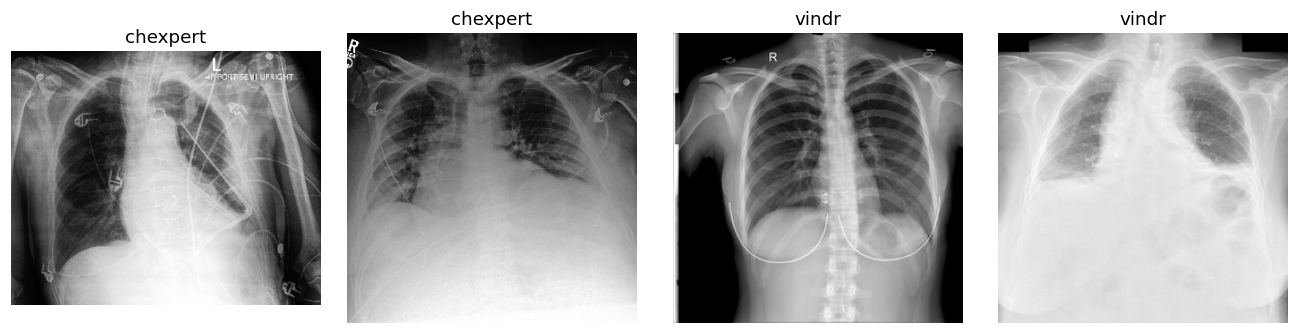

In [5]:
# Show valid label counts
rows = []
for source, group in [('combined', frame), *list(frame.groupby('source_dataset'))]:
    for label, target, mask in zip(LABELS, targets, masks):
        observed = group.loc[group[mask].eq(1), target]
        rows.append({'source': source, 'finding': label, 'observed': len(observed),
                     'positive': int(observed.sum()), 'negative': int((observed == 0).sum()),
                     'masked': int(group[mask].eq(0).sum())})
counts = pd.DataFrame(rows)
print(counts.to_string(index=False))

sample_indices = []
for target, mask in zip(targets, masks):
    candidates = frame.index[frame[target].eq(1) & frame[mask].eq(1) & ~frame.index.isin(sample_indices)]
    sample_indices.append(int(candidates[0]) if len(candidates) else None)
display_indices = []
for source in ['chexpert', 'vindr']:
    candidates = frame.index[frame['source_dataset'].eq(source)]
    display_indices.extend(candidates[:2].tolist())
fig, axes = plt.subplots(1, len(display_indices), figsize=(12, 3))
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    for ax, index in zip(axes, display_indices):
        with Image.open(io.BytesIO(archive.read(frame.loc[index, 'image_path']))) as image:
            ax.imshow(image.convert('L'), cmap='gray')
        ax.set_title(frame.loc[index, 'source_dataset'])
        ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'figures/sample_images.png', dpi=150)
plt.show()
plt.close(fig)


In [6]:
# Download and verify the pinned released checkpoint and four official prompts
from huggingface_hub import snapshot_download
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

download_start = time.perf_counter()
MODEL_DIR = Path(snapshot_download(
    MODEL_ID,
    revision=MODEL_REVISION,
    allow_patterns=['*.py', 'config.json', 'preprocessor_config.json', 'tokenizer.json',
                    'tokenizer_config.json', 'special_tokens_map.json', 'vocab.txt',
                    'model.safetensors', 'data/Chexpert/chexpert5_test_text.json'],
    max_workers=2,
))
download_seconds = time.perf_counter() - download_start
checkpoint_hash = sha256_file(MODEL_DIR / 'model.safetensors')
if checkpoint_hash != '7f8edcce8dbc42db753b0b110ab7eb7d5814825733b796f930973c46ee95c622':
    raise ValueError('The checkpoint differs from the verified official release.')
prompt_data = json.loads((MODEL_DIR / 'data/Chexpert/chexpert5_test_text.json').read_text())
PROMPTS = [prompt_data[str(index)][0] for index in PROMPT_INDICES]
expected_prompts = ['There is Atelectasis', 'There is Cardiomegaly',
                    'There is Pulmonary Consolidation', 'There is Pleural Effusion']
if PROMPTS != expected_prompts:
    raise ValueError(f'Official prompt order changed: {PROMPTS}')
print(f'Released model ready in {download_seconds / 60:.1f} minutes.')


Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

common_layers.py:   0%|          | 0.00/935 [00:00<?, ?B/s]

align_transformers.py: 0.00B [00:00, ?B/s]

configuration_radzero.py: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

utils.py: 0.00B [00:00, ?B/s]

vision_encoders.py:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Released model ready in 0.1 minutes.


In [7]:
# Load the released 518-pixel processor, tokenizer, and full model in FP32
model_start = time.perf_counter()
image_processor = AutoImageProcessor.from_pretrained(str(MODEL_DIR))
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR))
if image_processor.size != {'height': 518, 'width': 518}:
    raise ValueError('The released processor must use 518 x 518 images.')
tokenized_prompts = tokenizer(PROMPTS, padding=True, truncation=True, return_tensors='pt')
model, loading_info = AutoModel.from_pretrained(
    str(MODEL_DIR), trust_remote_code=True, torch_dtype=torch.float32,
    output_loading_info=True,
)
loading_errors = {key: loading_info.get(key)
                  for key in ['missing_keys', 'unexpected_keys', 'mismatched_keys', 'error_msgs']
                  if loading_info.get(key)}
if loading_errors:
    raise RuntimeError(f'The released checkpoint did not load completely: {loading_errors}')
model.eval().requires_grad_(False)
model = model.to('cuda:0')
model_seconds = time.perf_counter() - model_start
print(f'Full RadZero model loaded in {model_seconds / 60:.1f} minutes | {len(PROMPTS)} prompts')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Full RadZero model loaded in 0.3 minutes | 4 prompts


In [8]:
# Read archived images with a separate ZIP handle in each data worker
class CombinedImages(Dataset):
    def __init__(self, zip_path, image_paths):
        self.zip_path = str(zip_path)
        self.image_paths = list(image_paths)
        self.archive = None

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        if self.archive is None:
            self.archive = zipfile.ZipFile(self.zip_path)
        with Image.open(io.BytesIO(self.archive.read(self.image_paths[index]))) as image:
            pixels = np.asarray(image.convert('L'))
        normalized = cv2.normalize(pixels, None, 0, 255, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_8U)
        return Image.fromarray(normalized)

def collate_images(images):
    processed = image_processor(images)
    return torch.from_numpy(np.asarray(processed['pixel_values'], dtype=np.float32))

test_dataset = CombinedImages(ARCHIVE_PATH, frame['image_path'])
test_loader = DataLoader(
    test_dataset, batch_size=INFERENCE_BATCH_SIZE, shuffle=False, drop_last=False,
    num_workers=NUM_WORKERS, pin_memory=True, collate_fn=collate_images,
    persistent_workers=NUM_WORKERS > 0,
)


In [9]:
# Use the official scoring method on two T4 GPUs and check score agreement
class RadZeroClassifier(nn.Module):
    def __init__(self, official_model, prompts):
        super().__init__()
        self.model = official_model
        self.register_buffer('prompt_ids', prompts['input_ids'], persistent=False)
        self.register_buffer('prompt_mask', prompts['attention_mask'], persistent=False)

    @torch.no_grad()
    def forward(self, pixel_values):
        prompts = {'input_ids': self.prompt_ids, 'attention_mask': self.prompt_mask}
        output = self.model.compute_logits(pixel_values, [prompts])
        return output['logits'].reshape(pixel_values.shape[0], len(LABELS))

classifier = RadZeroClassifier(model, tokenized_prompts).to('cuda:0').eval()
parallel_model = nn.DataParallel(classifier, device_ids=[0, 1]).eval()
check_pixels = collate_images([test_dataset[i] for i in range(4)]).to('cuda:0')
with torch.no_grad():
    direct_scores = classifier(check_pixels)
    parallel_scores = parallel_model(check_pixels)
    singleton_scores = classifier(check_pixels[:1])
if not torch.isfinite(parallel_scores).all():
    raise ValueError('Non-finite RadZero scores were detected.')
if not torch.allclose(direct_scores, parallel_scores, atol=1e-4, rtol=1e-4):
    raise ValueError('Single-GPU and two-GPU scores disagree.')
if not torch.allclose(direct_scores[:1], singleton_scores, atol=1e-4, rtol=1e-4):
    raise ValueError('Singleton and batched scores disagree.')
del check_pixels, direct_scores, parallel_scores, singleton_scores
test_dataset.archive.close()
test_dataset.archive = None
for device in range(2):
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)
print('Score checks passed.')


Score checks passed.


/tmp/radzero_cache/modules/transformers_modules/1e6e7d6295a13aa0a4a7e1c1e2bb36b9ef4e02e8/losses.py:210: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4480.)
  logits = logits.T


In [10]:
# Score every held-out test image and report measured inference progress
inference_start = time.perf_counter()
score_batches = []
processed_images = 0
next_log = 250
with torch.no_grad():
    for batch_index, pixels in enumerate(test_loader, start=1):
        scores = parallel_model(pixels.to('cuda:0', non_blocking=True))
        score_batches.append(scores.float().cpu().numpy())
        processed_images += len(pixels)
        if processed_images >= next_log or processed_images == len(frame):
            for device in range(2):
                torch.cuda.synchronize(device)
            elapsed = time.perf_counter() - inference_start
            speed = processed_images / max(elapsed, 1e-9)
            remaining = (len(frame) - processed_images) / max(speed, 1e-9)
            print(f'{processed_images:,}/{len(frame):,} images | {speed:.1f} images/s | about {remaining / 60:.1f} min left', flush=True)
            next_log += 250
for device in range(2):
    torch.cuda.synchronize(device)
inference_seconds = time.perf_counter() - inference_start
raw_scores = np.concatenate(score_batches, axis=0)
truth = frame[targets].to_numpy(dtype=np.int64)
valid_mask = frame[masks].to_numpy(dtype=np.int64)
if raw_scores.shape != truth.shape or not np.isfinite(raw_scores).all():
    raise ValueError(f'Invalid score matrix shape: {raw_scores.shape}, expected {truth.shape}.')
probabilities = torch.from_numpy(raw_scores).sigmoid().numpy()
peak_memory_gb = [torch.cuda.max_memory_allocated(i) / 1024**3 for i in range(2)]
print(f'All test images scored in {inference_seconds / 60:.1f} minutes.')


256/2,501 images | 12.5 images/s | about 3.0 min left
504/2,501 images | 12.4 images/s | about 2.7 min left
752/2,501 images | 12.2 images/s | about 2.4 min left
1,000/2,501 images | 11.8 images/s | about 2.1 min left
1,256/2,501 images | 11.4 images/s | about 1.8 min left
1,504/2,501 images | 11.3 images/s | about 1.5 min left
1,752/2,501 images | 11.3 images/s | about 1.1 min left
2,000/2,501 images | 11.2 images/s | about 0.7 min left
2,256/2,501 images | 11.1 images/s | about 0.4 min left
2,501/2,501 images | 11.1 images/s | about 0.0 min left
All test images scored in 3.8 minutes.


In [11]:
# Save image predictions and evaluate observed labels by source
predictions = frame[['sample_id', 'source_dataset', 'image_path', *targets, *masks]].copy()
for column, label in enumerate(LABELS):
    key = targets[column].removeprefix('target_')
    predictions[f'logit_{key}'] = raw_scores[:, column]
    predictions[f'score_{key}'] = probabilities[:, column]
predictions.to_csv(RESULTS / 'predictions.csv', index=False)

metric_rows = []
for source in ['combined', 'chexpert', 'vindr']:
    source_rows = np.ones(len(frame), dtype=bool) if source == 'combined' else frame['source_dataset'].eq(source).to_numpy()
    for column, label in enumerate(LABELS):
        selection = source_rows & valid_mask[:, column].astype(bool)
        y_true = truth[selection, column]
        y_score = raw_scores[selection, column]
        y_pred = (probabilities[selection, column] >= THRESHOLD).astype(int)
        positives = int(y_true.sum())
        negatives = int(len(y_true) - positives)
        if positives and negatives:
            false_positive, true_positive, _ = roc_curve(y_true, y_score)
            auroc = float(auc(false_positive, true_positive))
            precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_score)
            auprc = float(auc(recall_curve, precision_curve))
        else:
            auroc = np.nan
            auprc = np.nan
        if len(y_true):
            precision, recall, f1, _ = precision_recall_fscore_support(
                y_true, y_pred, average='binary', zero_division=0)
            accuracy = float(accuracy_score(y_true, y_pred))
        else:
            precision = recall = f1 = accuracy = np.nan
        metric_rows.append({'source': source, 'finding': label, 'observed': len(y_true),
                            'positive': positives, 'negative': negatives, 'AUROC': auroc,
                            'AUPRC': auprc, 'accuracy': accuracy, 'precision': float(precision),
                            'recall': float(recall), 'F1': float(f1), 'threshold': THRESHOLD})
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(RESULTS / 'metrics_by_source.csv', index=False)
summary = (metrics.groupby('source')[['AUROC', 'AUPRC']].mean().round(3))
print(metrics[['source', 'finding', 'positive', 'negative', 'AUROC', 'AUPRC', 'F1']].round(3).to_string(index=False))
print()
print('Macro scores:')
print(summary.to_string())


  source          finding  positive  negative  AUROC  AUPRC    F1
combined      Atelectasis       150      2193  0.845  0.240 0.277
combined     Cardiomegaly       299      2166  0.833  0.388 0.395
combined    Consolidation        84      2283  0.857  0.178 0.186
combined Pleural Effusion       457      1999  0.943  0.752 0.715
chexpert      Atelectasis       139       704  0.677  0.271 0.332
chexpert     Cardiomegaly       109       856  0.858  0.404 0.267
chexpert    Consolidation        71       796  0.720  0.199 0.208
chexpert Pleural Effusion       384       572  0.860  0.756 0.719
   vindr      Atelectasis        11      1489  0.686  0.013 0.025
   vindr     Cardiomegaly       190      1310  0.948  0.738 0.656
   vindr    Consolidation        13      1487  0.894  0.046 0.105
   vindr Pleural Effusion        73      1427  0.945  0.713 0.691

Macro scores:
          AUROC  AUPRC
source                
chexpert  0.779  0.408
combined  0.869  0.389
vindr     0.868  0.377


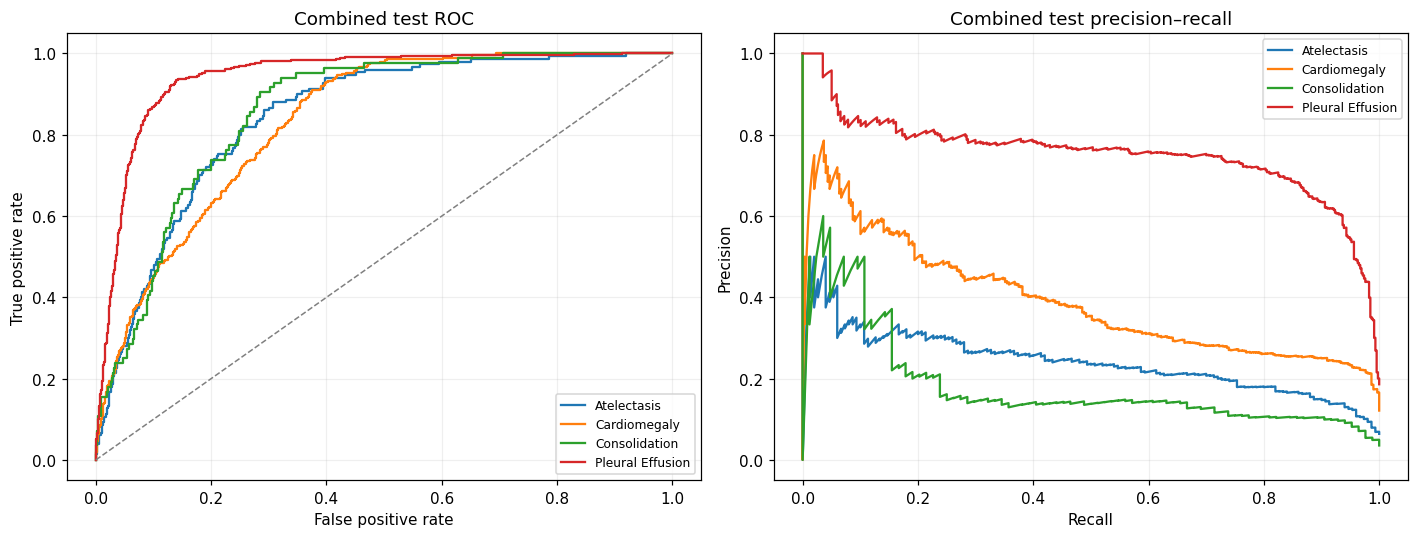

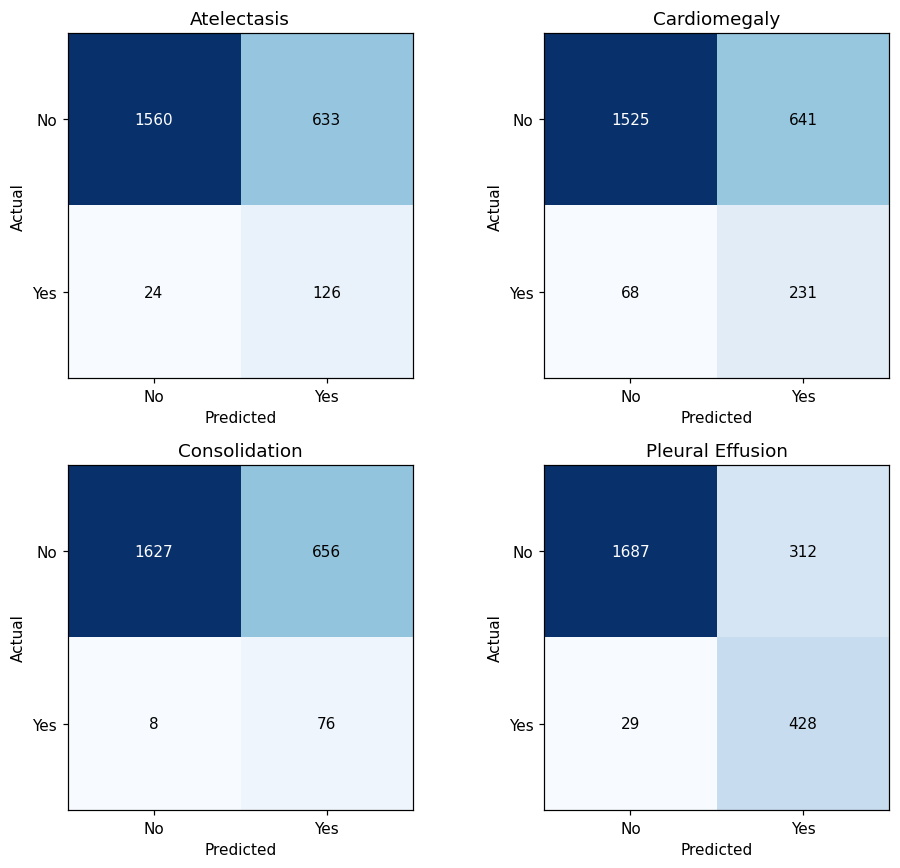

In [12]:
# Plot pooled ROC, precision-recall, and fixed-threshold confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for column, label in enumerate(LABELS):
    selection = valid_mask[:, column].astype(bool)
    y_true = truth[selection, column]
    y_score = raw_scores[selection, column]
    if len(np.unique(y_true)) != 2:
        continue
    false_positive, true_positive, _ = roc_curve(y_true, y_score)
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_score)
    axes[0].plot(false_positive, true_positive, label=label)
    axes[1].plot(recall_curve, precision_curve, label=label)
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(title='Combined test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Combined test precision–recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'figures/roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for column, label in enumerate(LABELS):
    selection = valid_mask[:, column].astype(bool)
    y_true = truth[selection, column]
    y_pred = (probabilities[selection, column] >= THRESHOLD).astype(int)
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax = axes.flat[column]
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for col in range(2):
            color = 'white' if matrix[row, col] > matrix.max() / 2 else 'black'
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center', color=color)
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1])
    ax.set_xticklabels(['No', 'Yes'])
    ax.set_yticklabels(['No', 'Yes'])
fig.tight_layout()
fig.savefig(RESULTS / 'figures/confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


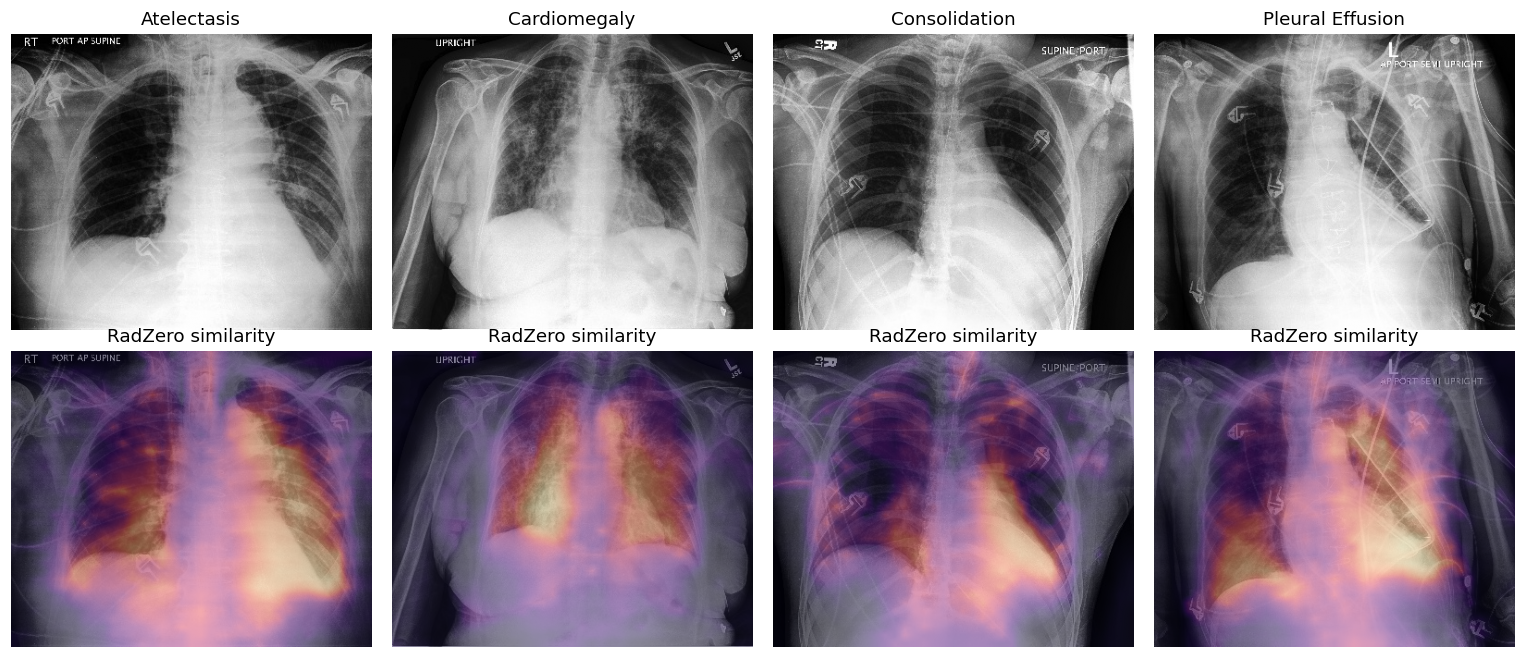

In [13]:
# Show four released-model similarity maps on positive test examples
spec = importlib.util.spec_from_file_location('radzero_visuals', MODEL_DIR / 'utils.py')
official_visuals = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official_visuals)
device_prompts = {key: value.to('cuda:0') for key, value in tokenized_prompts.items()}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
with torch.no_grad():
    for column, label in enumerate(LABELS):
        index = sample_indices[column]
        if index is None:
            axes[0, column].axis('off')
            axes[1, column].axis('off')
            continue
        image = test_dataset[index]
        pixels = collate_images([image]).to('cuda:0')
        output = model.compute_logits(pixels, [device_prompts])
        patch_scores = output['similarity_scores'][0, column]
        similarity_map = official_visuals.interpolate_similarity_scores(
            patch_scores, (image.height, image.width), image_processor,
        ).sigmoid()[0].cpu().numpy()
        axes[0, column].imshow(image, cmap='gray')
        axes[1, column].imshow(image, cmap='gray')
        axes[1, column].imshow(similarity_map, cmap='magma', alpha=0.5, vmin=0, vmax=1)
        axes[0, column].set_title(label)
        axes[1, column].set_title('RadZero similarity')
        axes[0, column].axis('off')
        axes[1, column].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'figures/similarity_maps.png', dpi=160)
plt.show()
plt.close(fig)


In [14]:
# Save the run settings and measured computation time
config = {
    'model': MODEL_ID, 'model_revision': MODEL_REVISION, 'checkpoint_sha256': checkpoint_hash,
    'dataset_zip': str(ARCHIVE_PATH), 'protocol': 'combined CheXpert–VinDr zero-shot test',
    'labels': LABELS, 'prompts': PROMPTS, 'test_images': len(frame),
    'input_size': image_processor.size, 'dtype': 'float32', 'batch_size': INFERENCE_BATCH_SIZE,
    'workers': NUM_WORKERS, 'seed': SEED, 'epochs': 0, 'learning_rate': None,
    'fixed_sigmoid_threshold': THRESHOLD,
    'ranking_metrics': 'raw-logit AUROC and trapezoidal precision–recall area',
    'source_label_policy': settings,
}
timing = {
    'download_minutes': download_seconds / 60,
    'model_load_minutes': model_seconds / 60,
    'test_inference_minutes': inference_seconds / 60,
    'total_notebook_minutes': (time.perf_counter() - RUN_START) / 60,
    'peak_gpu_memory_gb': peak_memory_gb,
    'combined_dataset_training_minutes': 0,
}
(RESULTS / 'config.json').write_text(json.dumps(config, indent=2, default=str))
(RESULTS / 'timing.json').write_text(json.dumps(timing, indent=2))
print('Results:', RESULTS)
print(f"Total notebook time: {timing['total_notebook_minutes']:.1f} minutes")
print('Training time: 0 minutes')


Results: /kaggle/working/radzero_combined_chexpert_vindr
Total notebook time: 5.2 minutes
Training time: 0 minutes
